# Лабораторная работа №2. Просодика

**Курс:** «Синтез речи», Университет ИТМО, 2026  
**Корпус:** RUSLAN  

Работа продолжает лабораторную №1: очищенные тексты сопоставляются с аудио на уровне слов, из аудио извлекаются паузы, а затем по одному только тексту предсказываются наличие и длительность пауз.

## 1. Постановка задачи

Необходимо решить две связанные задачи:

1. выполнить автоматическую пословную разметку корпуса RUSLAN — определить начало и конец каждого слова в WAV;
2. определить реальные межсловные паузы и их длительность;
3. построить модель, которая по текстовым признакам предсказывает место паузы;
4. для предсказанной паузы оценить её длительность в миллисекундах;
5. сравнить обученную модель с простым правилом на основе пунктуации.

## 2. Входные данные и признаки

Входом этапа разметки являются результаты первой лабораторной:

- `id` аудиозаписи;
- исходный и нормализованный текст;
- монофонический WAV, 16-bit PCM, 22 050 Гц.

Объектом классификации является каждая граница между соседними словами. Для неё используются признаки:

- левое и правое слово;
- префиксы, суффиксы, длина и количество гласных соседних слов;
- регистр первой буквы;
- знак препинания между словами;
- относительная позиция границы во фразе;
- части речи, падеж, число и род соседних слов;
- пара частей речи слева и справа.

Целевая переменная классификации — наличие акустической паузы. Цель регрессии — её длительность в миллисекундах.

In [1]:
from pathlib import Path
import csv
import json
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'labs' / 'lab2_pauses' / 'align_words.py').is_file():
            return candidate
    raise FileNotFoundError('Запустите блокнот из клонированного репозитория tts_labs_itmo')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
LAB_DIR = PROJECT_ROOT / 'labs' / 'lab2_pauses'
DATA_DIR = PROJECT_ROOT / 'data' / 'lab2_pauses'
METADATA = PROJECT_ROOT / 'data' / 'metadata_RUSLAN_22200_normalized.csv'
ALIGNMENTS = DATA_DIR / 'word_alignments.csv'
STATUS = DATA_DIR / 'alignment_status.csv'
PAUSES = DATA_DIR / 'pause_boundaries.csv'
MODEL = DATA_DIR / 'pause_model.joblib'
METRICS = DATA_DIR / 'model_metrics.json'
FIGURE = DATA_DIR / 'pause_distribution.png'

if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

from analyze_pause_data import make_figure, summarize
from pause_model import PausePredictor, text_boundary_rows
from train_pause_model import train

print('Корень проекта:', PROJECT_ROOT)
print('Метаданные:', METADATA.is_file())
print('Разметка слов:', ALIGNMENTS.is_file())

C:\work projects\ITMO\tts_labs_itmo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Корень проекта: C:\work projects\ITMO\tts_labs_itmo
Метаданные: True
Разметка слов: True


## 3. Пословное выравнивание

Используется CTC forced alignment с русскоязычной моделью Wav2Vec2. В отличие от свободного распознавания, модель не создаёт новую расшифровку: ей передаётся проверенный нормализованный текст, а динамическое программирование ищет наиболее вероятный путь этого точного текста по акустическим кадрам.

Перед выравниванием WAV передискретизируется с 22 050 до 16 000 Гц — частоты, ожидаемой акустической моделью. Для каждого слова сохраняются:

- `start_s`, `end_s` — временные координаты;
- `confidence` — средняя CTC-уверенность букв слова;
- `boundary_after_s` — положение CTC-токена пробела после слова.

Полный запуск вынесен в `align_words.py`, потому что создание разметки всего корпуса является длительной одноразовой операцией. Скрипт поддерживает GPU, пакетную обработку и продолжение с контрольной точки.

In [2]:
# Воспроизводимая команда полного выравнивания. Она не запускается повторно,
# если готовые CSV уже существуют.
alignment_command = [
    sys.executable,
    str(LAB_DIR / 'align_words.py'),
    '--offline', '--resume', '--device', 'cuda', '--dtype', 'float16', '--batch-size', '16', '--max-batch-mb', '4.5', '--sort-by-duration',
]
print(' '.join(alignment_command))

C:\work projects\ITMO\tts_labs_itmo\.venv\Scripts\python.exe C:\work projects\ITMO\tts_labs_itmo\labs\lab2_pauses\align_words.py --offline --resume --device cuda --dtype float16 --batch-size 16 --max-batch-mb 4.5 --sort-by-duration


In [3]:
status_df = pd.read_csv(STATUS)
words_df = pd.read_csv(ALIGNMENTS)
alignment_summary = pd.DataFrame({
    'показатель': ['Записей в статусе', 'Успешно выровнено', 'Ошибок', 'Размечено слов'],
    'значение': [
        len(status_df),
        int((status_df['status'] == 'ok').sum()),
        int((status_df['status'] != 'ok').sum()),
        len(words_df),
    ],
})
display(alignment_summary)
display(words_df.head(10))

,показатель,значение
0,Записей в статусе,22100
1,Успешно выровнено,22100
2,Ошибок,0
3,Размечено слов,254972


,utterance_id,word_index,word,start_s,end_s,confidence,boundary_after_s
0,000000_RUSLAN,0,С,0.040446,0.060669,0.999989,0.091004
1,000000_RUSLAN,1,тревожным,0.141562,0.667362,0.999997,0.717919
2,000000_RUSLAN,2,чувством,0.768477,1.193162,0.999993,1.284166
3,000000_RUSLAN,3,берусь,1.334723,1.678516,0.999816,1.688627
4,000000_RUSLAN,4,я,1.739185,1.759408,0.999997,1.809966
5,000000_RUSLAN,5,за,1.860523,1.921193,0.999986,1.951527
6,000000_RUSLAN,6,перо,2.002085,2.163870,0.999968,NaN
7,000001_RUSLAN,0,Кого,0.020124,0.241493,0.999753,0.472924
8,000001_RUSLAN,1,интересуют,0.503111,1.086719,0.904736,1.137030
9,000001_RUSLAN,2,признания,1.167217,1.670328,0.943205,1.740763


## 4. Извлечение акустических пауз

CTC blank нельзя напрямую считать паузой: blank появляется и внутри протяжённых фонем. Поэтому CTC используется только для локализации межсловной границы, а длительность тишины измеряется непосредственно по WAV.

Алгоритм:

1. между последней буквой левого и первой буквой правого слова выделяется участок WAV;
2. сигнал делится на неперекрывающиеся окна по 10 мс;
3. для каждого окна рассчитывается RMS в dBFS;
4. тихим считается окно не выше −40 dBFS;
5. выбирается непрерывный тихий участок рядом с CTC-токеном пробела;
6. акустической паузой считается тишина длительностью не менее 80 мс.

Порог выбран по пилотной выборке и распределению межсловных интервалов. Он отделяет короткие артикуляционные переходы от воспринимаемой остановки речи.

In [4]:
# Команда, которой создана таблица границ:
print(sys.executable, LAB_DIR / 'extract_pauses.py', '--min-pause-ms 80 --silence-dbfs -40')
pauses_df = pd.read_csv(PAUSES)
display(pauses_df.head(10))

C:\work projects\ITMO\tts_labs_itmo\.venv\Scripts\python.exe C:\work projects\ITMO\tts_labs_itmo\labs\lab2_pauses\extract_pauses.py --min-pause-ms 80 --silence-dbfs -40


,utterance_id,boundary_index,left_word,right_word,punctuation,position_ratio,ctc_gap_s,ctc_gap_ms,gap_s,gap_ms,has_pause,left_confidence,right_confidence
0,000000_RUSLAN,0,С,тревожным,NONE,0.142857,0.080893,80.893,0.079819,79.819,0,0.999989,0.999997
1,000000_RUSLAN,1,тревожным,чувством,NONE,0.285714,0.101115,101.115,0.039909,39.909,0,0.999997,0.999993
2,000000_RUSLAN,2,чувством,берусь,NONE,0.428571,0.141561,141.561,0.029932,29.932,0,0.999993,0.999816
3,000000_RUSLAN,3,берусь,я,NONE,0.571429,0.060669,60.669,0.000000,0.000,0,0.999816,0.999997
4,000000_RUSLAN,4,я,за,NONE,0.714286,0.101115,101.115,0.000000,0.000,0,0.999997,0.999986
5,000000_RUSLAN,5,за,перо,NONE,0.857143,0.080892,80.892,0.049887,49.887,0,0.999986,0.999968
6,000001_RUSLAN,0,Кого,интересуют,NONE,0.200000,0.261618,261.618,0.049887,49.887,0,0.999753,0.904736
7,000001_RUSLAN,1,интересуют,признания,NONE,0.400000,0.080498,80.498,0.039909,39.909,0,0.904736,0.943205
8,000001_RUSLAN,2,признания,литературного,NONE,0.600000,0.100622,100.622,0.000000,0.000,0,0.943205,0.999989
9,000001_RUSLAN,3,литературного,неудачника,NONE,0.800000,0.060374,60.374,0.000000,0.000,0,0.999989,0.999994


## 5. Анализ пауз

,показатель,значение
0,Выровнено фраз,22100.000000
1,Межсловных границ,232872.000000
2,Найдено пауз,48561.000000
3,Доля пауз,0.208531
4,"Медианная длительность, мс",209.524000
5,"Средняя длительность, мс",257.378857


,boundaries,pauses,pause_rate,median_pause_ms,mean_pause_ms
NONE,185135.0,14243.0,0.076933,139.683,173.451923
",",18950.0,10268.0,0.541847,199.546,253.293651
.,12583.0,11845.0,0.941349,279.365,314.653384
—,3782.0,2482.0,0.656267,249.433,291.939233
…,2376.0,2181.0,0.917929,259.410,298.990344
...,...,...,...,...,...
"…»,",1.0,1.0,1.000000,768.254,768.254000
…».,1.0,1.0,1.000000,269.388,269.388000
…»«…,1.0,1.0,1.000000,658.503,658.503000
…»?,1.0,1.0,1.000000,798.186,798.186000


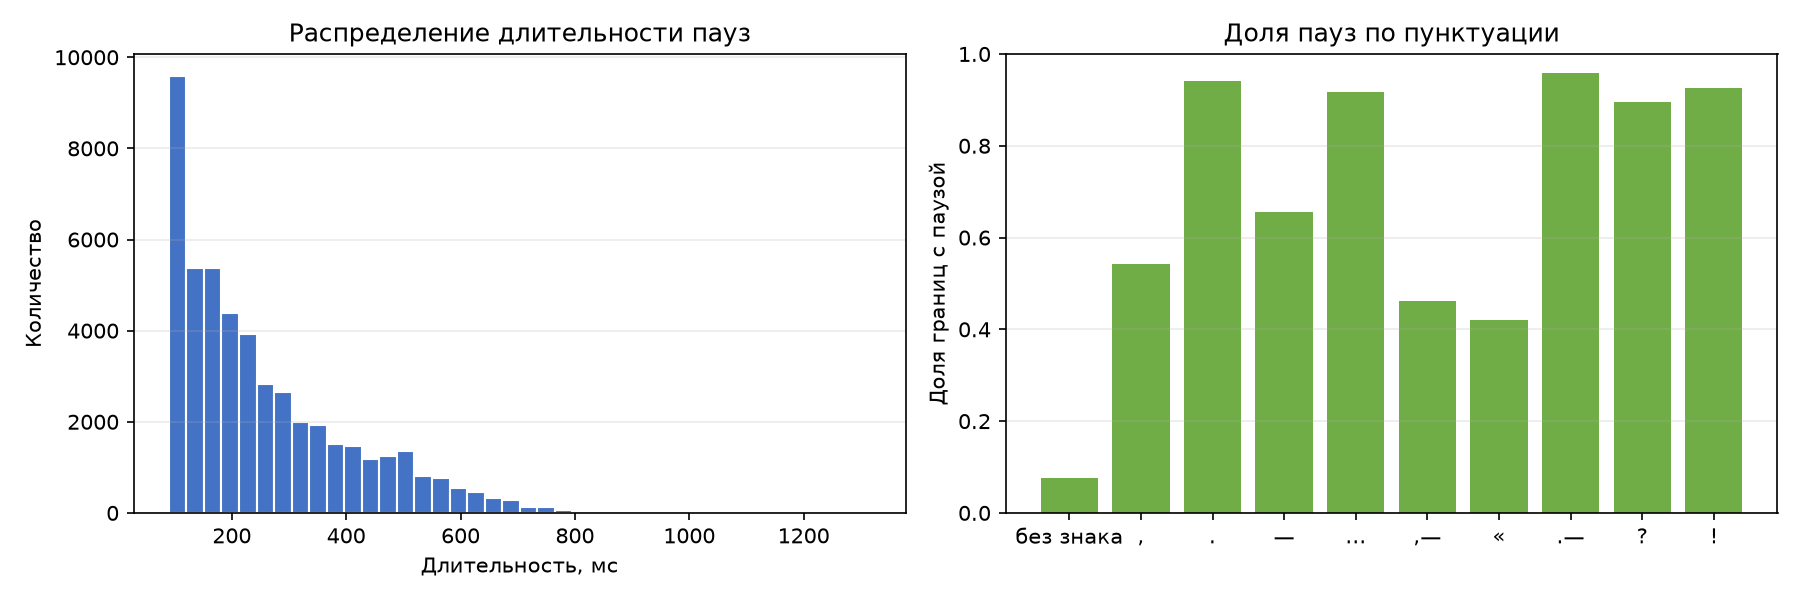

In [5]:
pause_summary = summarize(PAUSES, STATUS)
make_figure(PAUSES, FIGURE)
summary_table = pd.DataFrame([
    ['Выровнено фраз', pause_summary['utterances_aligned']],
    ['Межсловных границ', pause_summary['boundaries']],
    ['Найдено пауз', pause_summary['pauses']],
    ['Доля пауз', pause_summary['pause_rate']],
    ['Медианная длительность, мс', pause_summary['median_pause_ms']],
    ['Средняя длительность, мс', pause_summary['mean_pause_ms']],
], columns=['показатель', 'значение'])
display(summary_table)
display(pd.DataFrame(pause_summary['by_punctuation']).T.sort_values('boundaries', ascending=False))
display(Image(filename=str(FIGURE)))

## 6. Модель предсказания

Решение разделено на две модели:

1. логистическая регрессия определяет, существует ли пауза на границе;
2. Ridge-регрессия оценивает `log(1 + duration_ms)` только по положительным примерам.

Категориальные признаки преобразуются `DictVectorizer` в разреженную матрицу. Для компенсации дисбаланса классификатор использует `class_weight='balanced'`. Порог вероятности выбирается на отдельной валидационной части по максимальной F1; тестовая часть используется только для итоговой оценки.

Разделение выполняется через `GroupShuffleSplit` по `utterance_id`. Поэтому разные границы одной аудиозаписи не могут оказаться одновременно в обучении и тесте.

Baseline классификации считает паузой любую границу со знаком препинания. Baseline длительности всегда выдаёт медианную длительность пауз на обучающей части.

In [6]:
model_metrics = train(PAUSES, MODEL, METRICS, min_confidence=0.5)
classification_table = pd.DataFrame([
    {'модель': 'Пунктуационный baseline', **model_metrics['baseline']},
    {'модель': 'Логистическая регрессия', **model_metrics['classifier']},
])
display(classification_table)
display(pd.DataFrame([
    ['Baseline MAE длительности, мс', model_metrics['duration_baseline_mae_ms']],
    ['MAE длительности модели, мс', model_metrics['duration_mae_ms']],
    ['Положительных тестовых примеров', model_metrics['duration_test_examples']],
    ['Порог классификации', model_metrics['classification_threshold']],
], columns=['метрика', 'значение']))

,модель,precision,recall,f1
0,Пунктуационный baseline,0.726817,0.706755,0.716646
1,Логистическая регрессия,0.769197,0.717236,0.742308


,метрика,значение
0,"Baseline MAE длительности, мс",116.619841
1,"MAE длительности модели, мс",102.568982
2,Положительных тестовых примеров,9637.000000
3,Порог классификации,0.670000


## 7. Применение к новому тексту

In [7]:
predictor = PausePredictor(MODEL)
example_text = 'Сегодня хорошая погода, но вечером возможен дождь.'
prediction_df = pd.DataFrame(predictor.predict_text(example_text))
print(example_text)
display(prediction_df)

Сегодня хорошая погода, но вечером возможен дождь.


,boundary_index,left_word,right_word,punctuation,position_ratio,pause_probability,has_pause,duration_ms
0,0,Сегодня,хорошая,NONE,0.142857,0.145982,False,0.000000
1,1,хорошая,погода,NONE,0.285714,0.097581,False,0.000000
2,2,погода,но,",",0.428571,0.972396,True,303.165502
3,3,но,вечером,NONE,0.571429,0.011491,False,0.000000
4,4,вечером,возможен,NONE,0.714286,0.330692,False,0.000000
5,5,возможен,дождь,NONE,0.857143,0.155734,False,0.000000


## 8. Аудит и тесты

In [8]:
audit = subprocess.run(
    [sys.executable, str(LAB_DIR / 'audit_lab2.py'), '--require-complete'],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(audit.stdout)
print(audit.stderr)
assert audit.returncode == 0

tests = subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', str(LAB_DIR), '-p', 'test*.py', '-v'],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(tests.stdout)
print(tests.stderr)
assert tests.returncode == 0

Expected utterances: 22100
Recorded statuses: 22100
Aligned: 22100
Errors: 0
Missing statuses: 0
Unexpected statuses: 0
Duplicate status IDs: 0
Bad word groups: 0
Bad word timings: 0
Missing TextGrids: 0
Words with confidence < 0.5: 3353
Pause boundaries: 232872
Expected pause boundaries: 232872
Duplicate pause keys: 0





test_aligns_known_two_token_path (test_lab2_pauses.CTCAlignmentTests.test_aligns_known_two_token_path) ... ok
test_merges_characters_into_words (test_lab2_pauses.CTCAlignmentTests.test_merges_characters_into_words) ... ok
test_measures_longest_acoustic_silence (test_lab2_pauses.PauseExtractionTests.test_measures_longest_acoustic_silence) ... ok
test_number_of_boundaries_is_one_less_than_number_of_words (test_lab2_pauses.PauseExtractionTests.test_number_of_boundaries_is_one_less_than_number_of_words) ... ok
test_recovers_written_boundary_marks (test_lab2_pauses.PauseExtractionTests.test_recovers_written_boundary_marks) ... ok
test_builds_boundaries_for_new_text (test_lab2_pauses.PauseModelFeatureTests.test_builds_boundaries_for_new_text) ... ok
test_features_include_punctuation_position_and_morphology (test_lab2_pauses.PauseModelFeatureTests.test_features_include_punctuation_position_and_morphology) ... ok
test_stratified_examples_do_not_repeat_boundaries (test_lab2_pauses.ReviewSetTes

## 9. Выводы

In [9]:
display(Markdown(
    f"""В работе выполнено пословное CTC-выравнивание **{pause_summary['utterances_aligned']}** фраз и получено **{pause_summary['boundaries']}** межсловных границ. Акустический анализ обнаружил **{pause_summary['pauses']}** пауз с медианной длительностью **{pause_summary['median_pause_ms']:.1f} мс**.

Пунктуационный baseline достиг F1 = **{model_metrics['baseline']['f1']:.4f}**, обученная модель — F1 = **{model_metrics['classifier']['f1']:.4f}**. MAE предсказания длительности составила **{model_metrics['duration_mae_ms']:.1f} мс** против **{model_metrics['duration_baseline_mae_ms']:.1f} мс** у константного baseline.

Главное ограничение метода — акустические метки создаются автоматически и зависят от порогов тишины. Для контроля подготовлены TextGrid-файлы и стратифицированный набор коротких аудиофрагментов для ручного прослушивания."""
))

В работе выполнено пословное CTC-выравнивание **22100** фраз и получено **232872** межсловных границ. Акустический анализ обнаружил **48561** пауз с медианной длительностью **209.5 мс**.

Пунктуационный baseline достиг F1 = **0.7166**, обученная модель — F1 = **0.7423**. MAE предсказания длительности составила **102.6 мс** против **116.6 мс** у константного baseline.

Главное ограничение метода — акустические метки создаются автоматически и зависят от порогов тишины. Для контроля подготовлены TextGrid-файлы и стратифицированный набор коротких аудиофрагментов для ручного прослушивания.